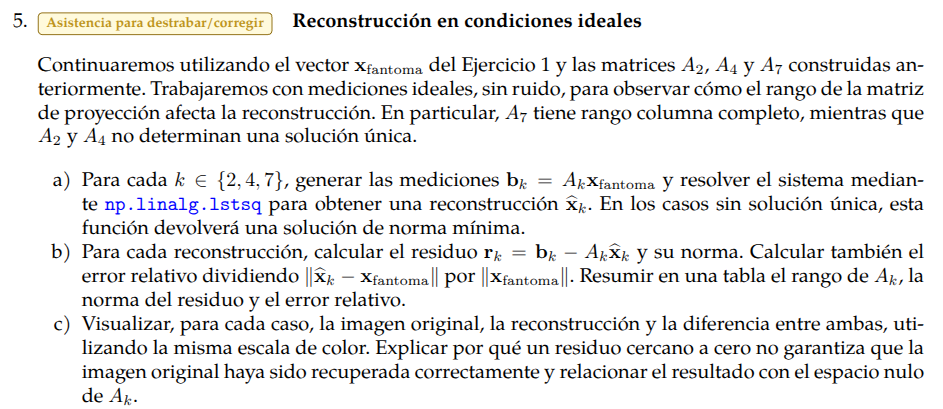

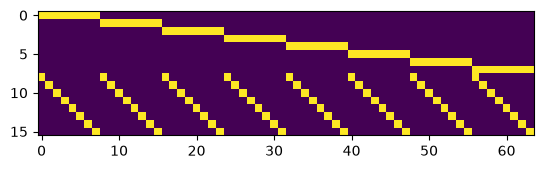

[0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
[0.  1.7 3.3 2.3 2.  2.4 1.4 0. ] [0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]


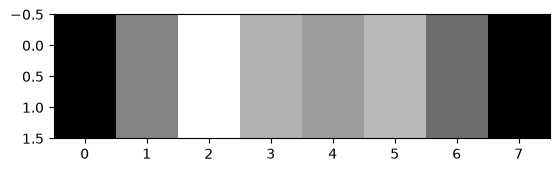

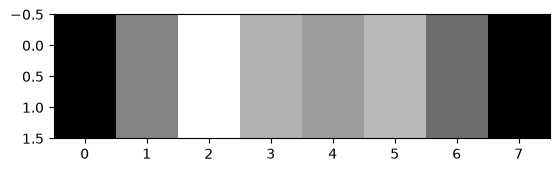

Dimensiones de A2:  (16, 64)
Dimensiones de A4:  (46, 64)
Dimensiones de A7:  (119, 64) 

Rango de A2:  15
Rango de A4:  39
Rango de A7:  64 

dim(Nul A2):  49
dim(Nul A4):  25
dim(Nul A7):  0 



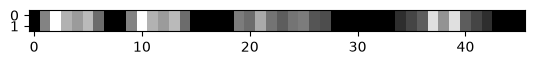

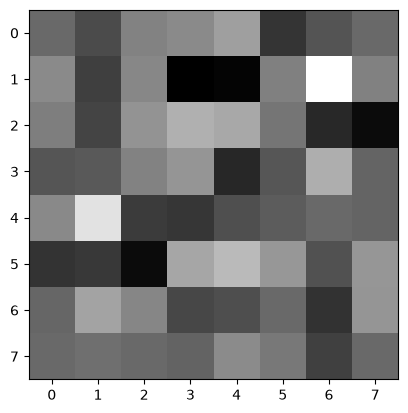

In [5]:
%run ejercicio_4.ipynb

119

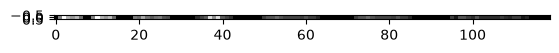

In [ ]:
b2 = A2 @ x_fantoma
b4 = A4 @ x_fantoma
b7 = A7 @ x_fantoma

plt.imshow([b2], cmap='gray')
plt.imshow([b4], cmap='gray')
plt.imshow([b7], cmap='gray')

In [7]:
x_2_approx = np.linalg.lstsq(A2, b2)[0]
x_4_approx = np.linalg.lstsq(A4, b4)[0]
x_7_approx = np.linalg.lstsq(A7, b7)[0]

In [8]:
X_2_approx = x_2_approx.reshape(8,8)
X_4_approx = x_4_approx.reshape(8,8)
X_7_approx = x_7_approx.reshape(8,8)

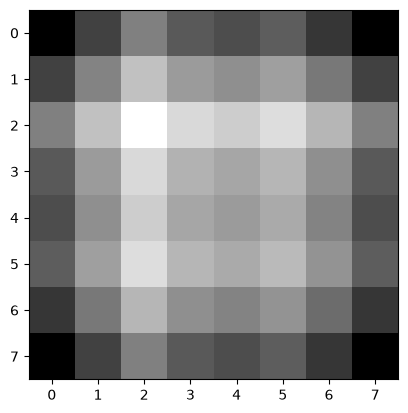

In [9]:
plt.imshow(X_2_approx, cmap="gray")

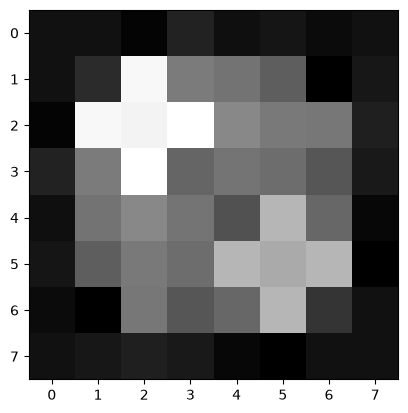

In [10]:
plt.imshow(X_4_approx, cmap="gray")

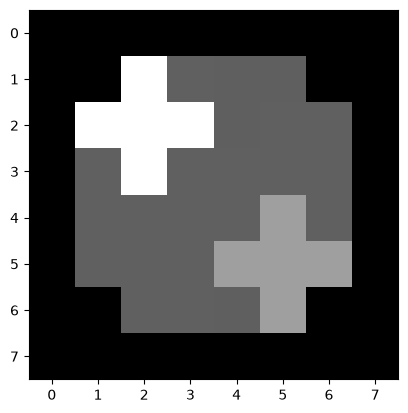

In [11]:
plt.imshow(X_7_approx, cmap="gray")

In [12]:
res_2 = b2 - (A2 @ x_2_approx)
res_4 = b4 - (A4 @ x_4_approx)
res_7 = b7 - (A7 @ x_7_approx)

res_7

array([-4.72603126e-16,  8.88178420e-16,  3.10862447e-15, -8.88178420e-16,
       -8.88178420e-16,  2.22044605e-15,  4.88498131e-15, -6.31439345e-16,
       -3.61580824e-16,  0.00000000e+00, -1.33226763e-15,  4.44089210e-16,
        5.32907052e-15,  3.99680289e-15, -4.44089210e-16, -5.20417043e-16,
       -3.54641930e-16,  0.00000000e+00,  2.05391260e-15, -4.44089210e-16,
        0.00000000e+00,  0.00000000e+00, -2.22044605e-16,  4.44089210e-16,
        1.77635684e-15, -1.77635684e-15,  3.99680289e-15,  1.22124533e-15,
        1.45022883e-15,  7.91033905e-16, -6.10622664e-16, -1.58900670e-15,
       -2.77555756e-16,  8.81239526e-16,  1.22124533e-15, -1.77635684e-15,
        4.21884749e-15,  2.22044605e-15,  1.77635684e-15,  8.88178420e-16,
        1.33226763e-15,  2.22044605e-16,  1.11022302e-16, -2.08166817e-16,
       -4.16333634e-16, -5.55111512e-17, -3.54641930e-16,  7.21644966e-16,
        1.05471187e-15, -1.44328993e-15, -2.22044605e-16,  1.33226763e-15,
        8.88178420e-16, -

In [13]:
err_rel_2 = np.linalg.norm(x_2_approx - x_fantoma)/np.linalg.norm(x_fantoma)
err_rel_4 = np.linalg.norm(x_4_approx - x_fantoma)/np.linalg.norm(x_fantoma)
err_rel_7 = np.linalg.norm(x_7_approx - x_fantoma)/np.linalg.norm(x_fantoma)

err_rel_7

np.float64(2.3282413405990266e-15)

In [14]:
rank_A2 = np.linalg.matrix_rank(A2)
rank_A4 = np.linalg.matrix_rank(A4)
rank_A7 = np.linalg.matrix_rank(A7)

In [20]:
import pandas as pd

In [27]:
tabla = pd.DataFrame({
    "rango": [rank_A2, rank_A4, rank_A7],
    "norma del residuo": [np.linalg.norm(res_2), np.linalg.norm(res_4), np.linalg.norm(res_7)],
    "error relativo": [round(float(err_rel_2), 2), round(float(err_rel_4), 2) , err_rel_7]
})

tabla

,rango,norma del residuo,error relativo
0,15,4.263192e-15,4.700000e-01
1,39,1.817407e-14,1.400000e-01
2,64,1.609639e-14,2.328241e-15


Un residuo cercano a cero no hace más que sugerir un vector factible tal que al aplicarse $A_k$ se asimile lo más que pueda a las mediciones en $b_k$. Por ende, es una aproximación y no garantiza que la imagen haya sido reconstruida pues no hay modo que eso ocurra salvo que $A_k$ sea invertible, es decir, que $\text{Dim}(\text{null}(A_k)) = 0$ (por teorema de la matriz invertible). 